In [117]:
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer  # Mandatory line
from sklearn.impute import IterativeImputer
import matplotlib.pyplot as plt


In [118]:
train = pd.read_csv("QSAR_challenge_train_80pct.csv")
train.head()

,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
0,2234-13-1,8.0,7.157,2.41,0.21,6.55,0.97,0.0,0.0,0.0,2.58,3
1,108-42-9,1.0,0.000,1.23,0.20,2.13,0.68,0.0,1.0,NaN,0.33,3
2,106-43-4,1.0,0.000,1.23,0.22,3.21,0.84,0.0,0.0,0.0,1.80,1
3,108-87-2,0.0,0.000,0.00,0.34,3.48,1.67,0.0,0.0,0.0,2.32,1
4,101-81-5,0.0,5.614,2.21,0.19,4.15,1.47,0.0,0.0,0.0,2.97,1


In [119]:
test = pd.read_csv("QSAR_challenge_test_20pct_NO_TARGETS.csv")
test.head()

,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O]
0,78-79-5,0.0,0.000,0.45,0.26,1.97,0.63,0.0,0.0,0.0
1,16606-02-3,3.0,6.173,2.31,0.20,5.47,1.23,0.0,0.0,0.0
2,111-44-4,2.0,0.000,0.00,0.35,1.59,0.81,0.0,0.0,0.0
3,107-05-1,1.0,0.000,0.24,0.38,1.67,0.41,0.0,0.0,NaN
4,555-03-3,0.0,0.000,1.48,0.14,1.70,0.88,0.0,1.0,5.0


In [120]:
train.describe()

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
count,612.000000,610.000000,616.000000,611.000000,610.000000,609.000000,604.000000,616.000000,607.000000,623.000000,623.000000
mean,1.754902,3.349279,1.532987,0.236563,3.189770,1.496700,0.188742,0.428571,3.598023,2.046260,1.736758
std,1.993950,2.970165,0.934499,0.156650,1.584938,0.854107,0.506154,0.495274,4.491267,1.335059,0.922066
min,0.000000,0.000000,0.000000,0.090000,-1.960000,0.140000,0.000000,0.000000,0.000000,-1.700000,1.000000
25%,0.000000,0.000000,1.210000,0.170000,2.190000,0.860000,0.000000,0.000000,0.000000,0.985000,1.000000
50%,1.000000,4.025000,1.380000,0.200000,3.115000,1.260000,0.000000,0.000000,2.000000,2.000000,1.000000
75%,3.000000,6.187500,2.280000,0.240000,4.207500,1.990000,0.000000,1.000000,6.000000,2.865000,3.000000
max,12.000000,9.316000,5.330000,2.230000,8.320000,7.190000,3.000000,1.000000,25.000000,5.930000,3.000000


In [121]:
display(train.info())
display(test.info())

<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sample_id              623 non-null    str    
 1   nHM                    612 non-null    float64
 2   piPC09                 610 non-null    float64
 3   PCD                    616 non-null    float64
 4   X2Av                   611 non-null    float64
 5   MLOGP                  610 non-null    float64
 6   ON1V                   609 non-null    float64
 7   N-072                  604 non-null    float64
 8   B02[C-N]               616 non-null    float64
 9   F04[C-O]               607 non-null    float64
 10  regression_target      623 non-null    float64
 11  classification_target  623 non-null    int64  
dtypes: float64(10), int64(1), str(1)
memory usage: 58.5 KB


None

<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   sample_id  156 non-null    str    
 1   nHM        153 non-null    float64
 2   piPC09     152 non-null    float64
 3   PCD        151 non-null    float64
 4   X2Av       153 non-null    float64
 5   MLOGP      154 non-null    float64
 6   ON1V       154 non-null    float64
 7   N-072      153 non-null    float64
 8   B02[C-N]   153 non-null    float64
 9   F04[C-O]   153 non-null    float64
dtypes: float64(9), str(1)
memory usage: 12.3 KB


None

In [122]:
def impute(data, drop_columns=['sample_id'], imputer=None):
  imputer = imputer or IterativeImputer(random_state=42)
  cleared = data.drop(columns=drop_columns)
  imputed = imputer.fit_transform(cleared)
  return pd.DataFrame(imputed, columns=cleared.columns, index=data.index)

imputation_test = impute(test)
imputation_train = impute(train)

In [123]:
def preprocess(df: pd.DataFrame) -> pd.DataFrame:
  df = df.copy()
  df["B02[C-N]"] = df["B02[C-N]"].round().clip(0, 1)
  df["piPC09_is_zero"] = (df["piPC09"] < 0.5).astype(float)
  for c in ["nHM", "N-072", "F04[C-O]"]:
    df[c] = np.log1p(df[c].clip(lower=0))
  return df

imputation_train = preprocess(imputation_train)

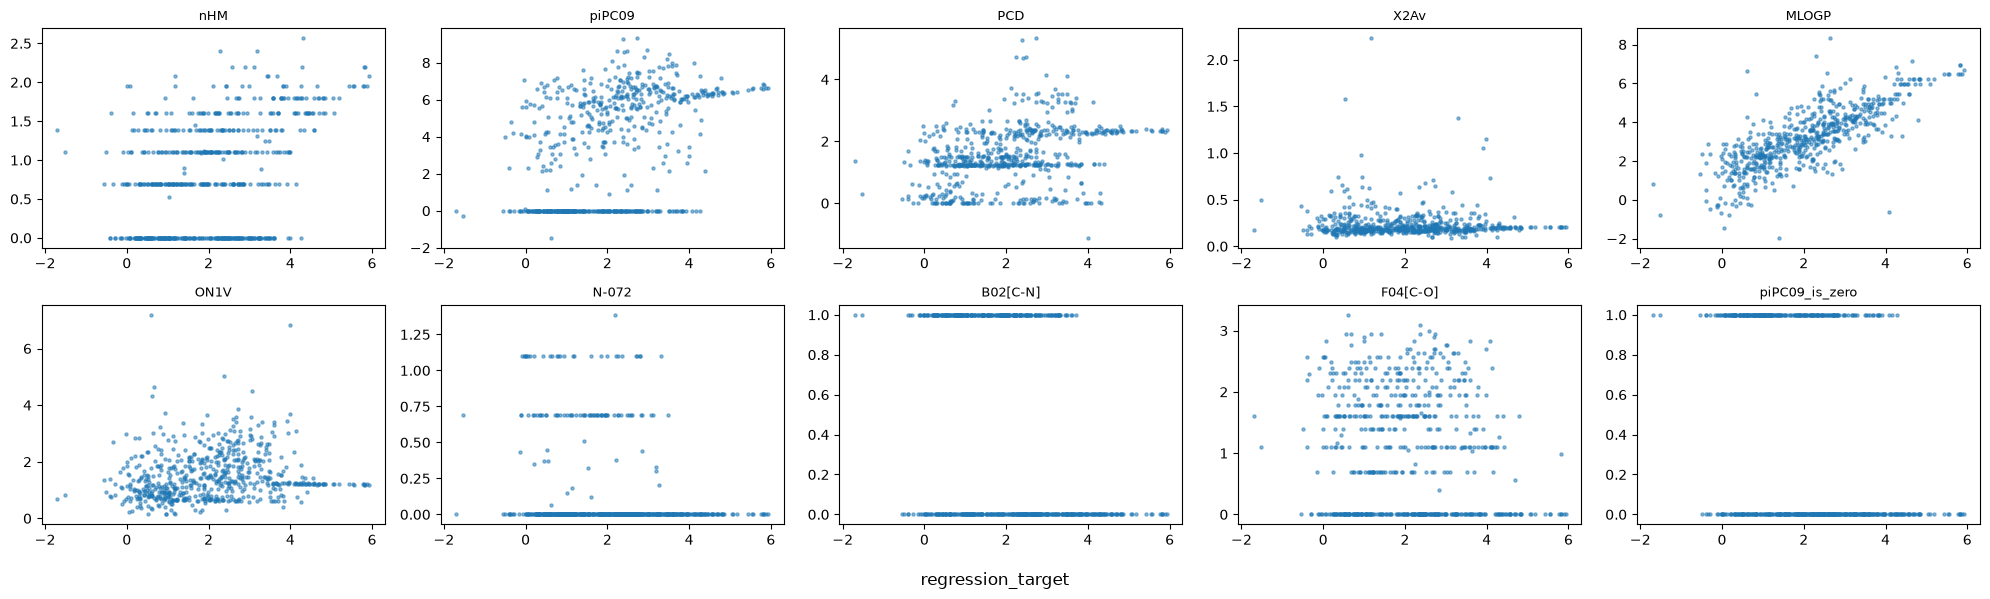

In [124]:
features = imputation_train.columns.drop(
    ["sample_id", "index", "classification_target", "regression_target"],
    errors="ignore",
)

ncols = 5
nrows = int(np.ceil(len(features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))

for ax, col in zip(axes.flat, features):
    ax.scatter(imputation_train["regression_target"], imputation_train[col], s=5, alpha=0.5)
    ax.set_title(col, fontsize=9)

for ax in axes.flat[len(features):]:
    ax.set_visible(False)

fig.supxlabel("regression_target")
plt.tight_layout()


In [125]:
imputation_train.corr(method="spearman")

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target,piPC09_is_zero
nHM,1.000000,0.061148,-0.009974,0.457252,0.307184,-0.252329,-0.101040,-0.210203,-0.061805,0.366116,-0.009686,-0.037701
piPC09,0.061148,1.000000,0.787204,-0.335964,0.532088,0.563536,0.108764,0.005077,0.234941,0.458319,0.207645,-0.872965
PCD,-0.009974,0.787204,1.000000,-0.568802,0.459147,0.237392,-0.001906,0.126353,0.177820,0.377079,0.107102,-0.549788
X2Av,0.457252,-0.335964,-0.568802,1.000000,-0.034727,-0.050476,-0.077607,-0.308481,-0.210694,0.043457,-0.013579,0.226033
MLOGP,0.307184,0.532088,0.459147,-0.034727,1.000000,0.277408,-0.229732,-0.362454,-0.139298,0.796496,0.193972,-0.405585
ON1V,-0.252329,0.563536,0.237392,-0.050476,0.277408,1.000000,0.281960,0.144188,0.466614,0.230079,0.299879,-0.669747
N-072,-0.101040,0.108764,-0.001906,-0.077607,-0.229732,0.281960,1.000000,0.435133,0.289877,-0.211282,0.007888,-0.231492
B02[C-N],-0.210203,0.005077,0.126353,-0.308481,-0.362454,0.144188,0.435133,1.000000,0.262406,-0.323257,-0.106883,-0.062563
F04[C-O],-0.061805,0.234941,0.177820,-0.210694,-0.139298,0.466614,0.289877,0.262406,1.000000,-0.109347,0.258218,-0.343487
regression_target,0.366116,0.458319,0.377079,0.043457,0.796496,0.230079,-0.211282,-0.323257,-0.109347,1.000000,-0.056580,-0.364141


In [ ]:
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer, SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_predict

feature_cols = train.columns.drop(["sample_id", "regression_target", "classification_target"])
X = train[feature_cols]
y = train["regression_target"]

pre = ColumnTransformer([
  ("spline", SplineTransformer(degree=4, knots="quantile", extrapolation="constant"),
   ["MLOGP", "PCD", "X2Av", "ON1V"]),
  ("linear", StandardScaler(), ["piPC09", "nHM", "N-072", "F04[C-O]"]),
  ("binary", "passthrough", ["B02[C-N]", "piPC09_is_zero"]),
])

model = make_pipeline(
  IterativeImputer(random_state=42).set_output(transform="pandas"),
  FunctionTransformer(preprocess),
  pre,
  PolynomialFeatures(degree=2, include_bias=False),
  Ridge(alpha=5),
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# scores = cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
# print(-scores.mean(), scores.std())

search = GridSearchCV(
  model,
  {"polynomialfeatures__degree": [1, 2, 3], "ridge__alpha": [0.1, 1, 3, 5, 7, 10]},
  cv=cv,
  scoring="neg_root_mean_squared_error",
  n_jobs=-1,
  refit=True,
)
search.fit(X, y)
print(search.best_params_, -search.best_score_)


{'a__ridge__alpha': 3, 'b__ridge__alpha': 1} 0.6969911113427931


In [127]:
from sklearn.ensemble import RandomForestRegressor

rf = make_pipeline(
  IterativeImputer(random_state=42),
  RandomForestRegressor(random_state=42, n_jobs=-1),
)

rf_search = GridSearchCV(
  rf,
  {
    "randomforestregressor__n_estimators": [300],
    "randomforestregressor__max_depth": [None, 5, 10, 20],
    "randomforestregressor__min_samples_leaf": [1, 2, 5],
    "randomforestregressor__max_features": [1.0, 0.5, "sqrt"],
  },
  cv=cv,
  scoring="neg_root_mean_squared_error",
)
rf_search.fit(X, y)
print(rf_search.best_params_, -rf_search.best_score_)

{'randomforestregressor__max_depth': 20, 'randomforestregressor__max_features': 'sqrt', 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__n_estimators': 300} 0.6972199041962269


Text(0, 0.5, 'Residual')

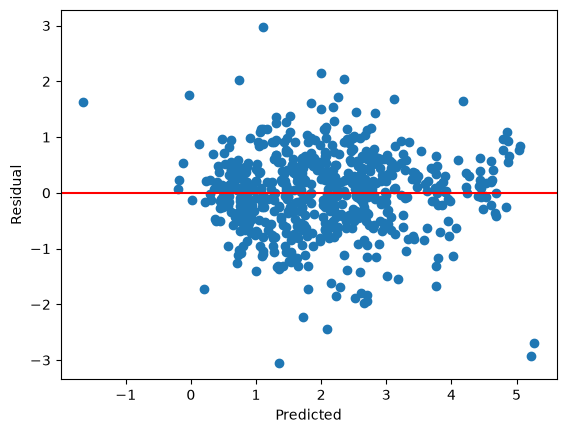

In [128]:
y_pred = cross_val_predict(search.best_estimator_, X, y, cv=cv)
residuals = y - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted")
plt.ylabel("Residual")

# Classification

In [129]:
y = train["classification_target"]
print(y.value_counts())

classification_target
1    368
3    204
2     51
Name: count, dtype: int64


In [130]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_search = GridSearchCV(
  make_pipeline(
    IterativeImputer(random_state=42),
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
  ),
  {
    "randomforestclassifier__max_depth": [None, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 2, 5],
    "randomforestclassifier__class_weight": [None, "balanced"],
  },
  cv=cv,
  scoring="f1_macro",
)
rf_search.fit(X, y)
print(rf_search.best_params_, rf_search.best_score_)


{'randomforestclassifier__class_weight': None, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1} 0.605272692118242


In [ ]:
from sklearn.linear_model import LogisticRegression

logreg_search = GridSearchCV(
  make_pipeline(
    IterativeImputer(random_state=42).set_output(transform="pandas"),
    FunctionTransformer(preprocess),
    clone(pre),
    PolynomialFeatures(degree=3, include_bias=False),
    LogisticRegression(max_iter=10000, random_state=42, solver="saga"),
  ),
  {
    "logisticregression__C": [0.25, 0.5, 1],
    "logisticregression__l1_ratio": [0.001, 0.01, 0.1]
  },
  cv=cv,
  scoring="f1_macro",
  n_jobs=-1,
)
logreg_search.fit(X, y)
print(logreg_search.best_params_, logreg_search.best_score_)


{'logisticregression__C': 1, 'logisticregression__l1_ratio': 0.001} 0.595885517407005


In [148]:
submission = pd.DataFrame({
    "sample_id": test["sample_id"],
})

submission["regression_prediction"] = search.predict(test[feature_cols])
submission["classification_prediction"] = logreg_search.predict(test[feature_cols])

display(submission.head())

,sample_id,regression_prediction,classification_prediction
0,78-79-5,0.655201,1
1,16606-02-3,4.330605,1
2,111-44-4,0.533501,1
3,107-05-1,0.497837,1
4,555-03-3,0.789083,1


In [149]:
import datetime
from pathlib import Path

timestamp = int(datetime.datetime.now().timestamp())
path = Path("data/output")

if not path.exists():
  path.mkdir(parents=True)

submission.to_csv(path / f"{timestamp}.csv", index=False)